# Extension 2 — Candidate Forecast Experiments

**Question:** on the new 2024–2026 candidate data, does anything beat *persistence* (next week's price = this week's price)?

| Section | Content |
|---|---|
| 1 | Target, split and metrics (frozen protocol) |
| 2 | Baselines: persistence vs seasonal naive vs climatology |
| 3 | The pre-registered learned model, and why it failed |
| 4 | The weather experiment, its coverage, and why weather was not adopted |
| 5 | What this means |

All scores here are on the **2026 validation window** (target Sundays 2026-01-04 → 2026-06-28). The test window is covered in Extension 3.

**Previous:** [Extension 1](Research_Extension_01_Candidate_Price_Data.ipynb) · **Next:** [Extension 3 — Final Persistence Test](Research_Extension_03_Final_Persistence_Test.ipynb) · **Original-data counterpart:** [Phase 8](Phase_08_Price_Forecasting.ipynb)

> **Status of this material.** Everything here is a **candidate experiment** (`candidate-prices-v1.1`, D-50), kept separate from the production Phase 1–10 pipeline. Nothing in this notebook is a production model, and nothing here changes the dashboard.

In [1]:
# Setup: locate the project root; read saved outputs only (no parquet, no network, no writes)
import hashlib, json, os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
C = Path("Processed_Data/candidates/datagov_prices")      # candidate data and experiments (not production)
EXP = C / "experiments"
CROPS = ["Onion", "Potato", "Wheat"]
COLORS = {"Onion": "#7b3294", "Potato": "#c2a5cf", "Wheat": "#e66101"}
print("Python", sys.version.split()[0])

Python 3.13.7


## 1. Protocol (frozen before any score was seen)

- **Target:** the median modal price of a series in the target week, 1 (primary), 2 or 4 weeks after the origin week.
- **Split:** by the Sunday of the target week, so no training target falls inside an evaluated period.
- **Metrics:** MAE in Rs/quintal (primary), RMSE, MAPE (with an instability flag), median absolute percentage error.
- **Uncertainty:** markets are resampled with replacement (cluster bootstrap, 10,000 replicates, seed 20261022), because rows from one market are not independent.

In [2]:
proto = json.loads((C / "experiment_design_v1_1/exp_candidate_v1_protocol.json").read_text())
lf = hashlib.sha256((C / "experiment_design_v1_1/exp_candidate_v1_protocol.json").read_bytes().replace(b"\r\n", b"\n")).hexdigest()
print("protocol SHA-256 (LF):", lf)
pd.DataFrame(proto["split_by_target_sunday"], index=["from", "to"]).T

protocol SHA-256 (LF): a6b1240c4c4f80da15a02fea946ca5f79f07617d9ccbabb7479ebb65193ae9ee


,from,to
test,2026-07-05,2026-10-18
train,None,2025-12-28
validation,2026-01-04,2026-06-28


## 2. Baselines

In [3]:
B = EXP / "exp_candidate_v1/baselines_phase8_quarterly"
base = pd.concat([pd.read_csv(B / f"faq_only_h{h}/by_crop.csv").assign(h=h) for h in (1, 2, 4)])
t = base.pivot_table(index=["Commodity", "h"], columns="model", values="mae").round(1)
t[["persistence", "seasonal_naive", "calendar_climatology"]]

model        persistence  seasonal_naive  calendar_climatology
Commodity h                                                   
Onion     1         95.6           578.0                 600.4
          2        142.9           578.7                 613.2
          4        230.5           577.7                 627.4
Potato    1         49.2           485.3                 577.3
          2         81.8           484.8                 579.9
          4        149.0           485.6                 580.1
Wheat     1         36.6           203.0                 163.5
          2         52.0           198.4                 164.7
          4         76.4           192.4                 174.5

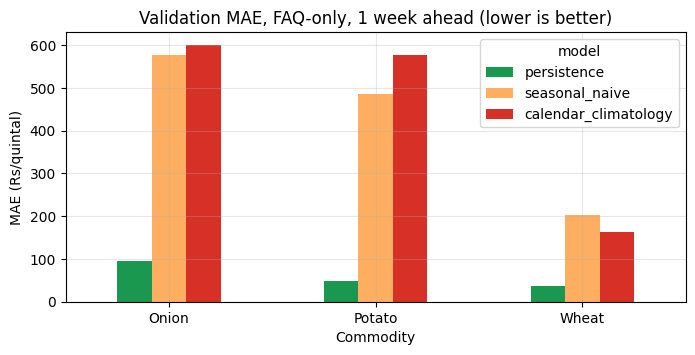

In [4]:
b1 = base[base.h == 1].pivot(index="Commodity", columns="model", values="mae")[["persistence", "seasonal_naive", "calendar_climatology"]]
ax = b1.plot.bar(figsize=(8, 3.5), rot=0, color=["#1a9850", "#fdae61", "#d73027"],
                 title="Validation MAE, FAQ-only, 1 week ahead (lower is better)")
ax.set_ylabel("MAE (Rs/quintal)"); plt.show()

**Persistence wins by a wide margin.** Seasonal naive and climatology are roughly 4–12× worse: with ~2.7 years of history, last year's price says little about next week's. Persistence is the default forecast (D-51).

## 3. The pre-registered learned model

One exploratory model was allowed: the Phase 8 conservative gradient boosting with a price-only weekly feature set, h = 1, FAQ-only. The rule fixed in advance: it must beat persistence in **both** validation quarters, with the 95% interval of skill above 0. Skill = 1 − MAE_model / MAE_persistence.

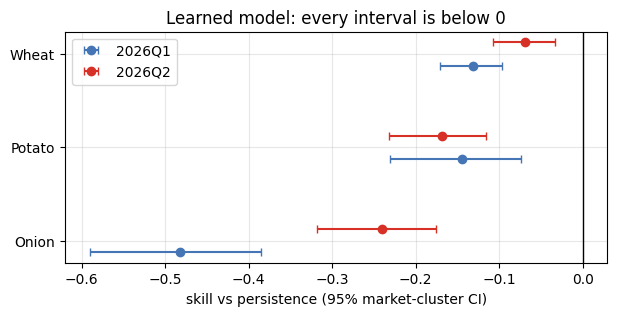

,crop,2026Q1_skill,2026Q2_skill,passes_preregistered_rule
0,Onion,-0.482,-0.240,False
1,Potato,-0.145,-0.168,False
2,Wheat,-0.131,-0.069,False


In [5]:
sel = pd.read_csv(EXP / "exp_candidate_v1/learned_hgb_conservative_faq_only_h1/run/selection.csv")
ci = lambda s: json.loads(s)
fig, ax = plt.subplots(figsize=(7, 3))
for i, (_, r) in enumerate(sel.iterrows()):
    for j, q in enumerate(["2026Q1", "2026Q2"]):
        lo, hi = ci(r[f"{q}_skill_ci95"]); y = i + (j - 0.5) * 0.25
        ax.errorbar(r[f"{q}_skill"], y, xerr=[[r[f"{q}_skill"] - lo], [hi - r[f"{q}_skill"]]], fmt="o", capsize=3,
                    color=["#4575b4", "#d73027"][j], label=q if i == 0 else None)
ax.axvline(0, color="k", lw=1); ax.set_yticks(range(len(sel)), sel.crop)
ax.set(xlabel="skill vs persistence (95% market-cluster CI)", title="Learned model: every interval is below 0"); ax.legend()
plt.show()
sel[["crop", "2026Q1_skill", "2026Q2_skill", "passes_preregistered_rule"]].round(3)

**Why it failed.** Weekly prices are dominated by last week's level; the model has ~46 weeks of eligible targets and must learn the *change* from noisy weekly medians. Phase 8 saw the same pattern with far more history (its one selected model lost 1.58% on the test years). By the pre-registration, no other setting may be tried on this validation window.

## 4. The weather experiment

A second pre-registered experiment added Open-Meteo district weather (`exp-candidate-weather-v1`). Weather exists only for the verified district points, so it could cover only part of the market panel:

In [6]:
rc = pd.read_csv(EXP / "exp_candidate_weather_v1/restricted_coverage.csv")
rc[["crop", "quarter", "eligible_rows", "weather_rows", "weather_row_pct", "weather_markets", "weather_states", "top_state", "top_state_share"]]

,crop,quarter,eligible_rows,weather_rows,weather_row_pct,weather_markets,weather_states,top_state,top_state_share
0,Onion,2026Q1,1038,204,19.7,20,6,West Bengal,0.382
1,Onion,2026Q2,938,247,26.3,22,7,West Bengal,0.308
2,Potato,2026Q1,1069,156,14.6,19,3,West Bengal,0.417
3,Potato,2026Q2,1010,210,20.8,17,3,West Bengal,0.529
4,Wheat,2026Q1,1292,255,19.7,23,3,Madhya Pradesh,0.545
5,Wheat,2026Q2,2039,413,20.3,29,4,Madhya Pradesh,0.552


In [7]:
acc = pd.read_csv(EXP / "exp_candidate_weather_v1/run/acceptance.csv")
rows = []
for _, r in acc.iterrows():
    for q in ("2026Q1", "2026Q2"):
        rows.append({"crop": r.crop, "quarter": q, "skill": r[f"{q}_skill"], "ci95": [round(x, 3) for x in ci(r[f"{q}_skill_ci95"])],
                     "ci_bonferroni": [round(x, 3) for x in ci(r[f"{q}_skill_ci_bonferroni"])], "pass": r[f"{q}_pass"]})
pd.DataFrame(rows).round(3)

,crop,quarter,skill,ci95,ci_bonferroni,pass
0,Onion,2026Q1,-0.173,"[-0.338, -0.065]","[-0.425, -0.041]",False
1,Onion,2026Q2,-0.479,"[-0.801, -0.257]","[-0.943, -0.201]",False
2,Potato,2026Q1,-0.152,"[-0.292, -0.035]","[-0.337, 0.003]",False
3,Potato,2026Q2,-0.346,"[-0.639, -0.178]","[-0.763, -0.126]",False
4,Wheat,2026Q1,-0.007,"[-0.032, 0.014]","[-0.044, 0.022]",False
5,Wheat,2026Q2,0.017,"[-0.024, 0.046]","[-0.04, 0.054]",False


**Why weather was not adopted (D-51).**
- It failed the acceptance rule for every crop: Onion and Potato were clearly worse than persistence, and Wheat was indistinguishable from it (intervals straddle 0).
- Only about 15–26% of eligible rows had weather, from 17–29 market clusters, so even a positive result would have generalised poorly.
- It was the second model on the same validation window, so a multiple-comparison caveat applies (hence the Bonferroni column).
- Weather stays out of the candidate and production forecasting pipeline.

## 5. What this means

On recent data, **persistence is the honest default** for weekly mandi prices. Both learned attempts were pre-registered, scored once and recorded as failures; nothing was tuned afterwards. The remaining question was how large persistence's error is on unseen weeks, which is Extension 3.